Датасет: 9 994 строки × 21 столбец, период 2014–2017, ритейл офисных товаров (US). Одна строка = позиция заказа.

# Этап 1. Загрузка и проверка качества данных

**Цель:** убедиться, что датасет пригоден для анализа, привести типы,
зафиксировать найденные проблемы и решения.

**Данные:** Sample - Superstore.csv — 9 994 строки × 21 столбец,
ритейл офисных товаров (US), период 2014–2017. Одна строка = позиция заказа.

## 1.1. Загрузка данных

Читаем CSV с кодировкой `cp1251` Смотрим размер, первые/последние строки и типы.

In [117]:
import pandas as pd

pd.set_option("display.max_columns", 30)

In [118]:
df = pd.read_csv('Sample - Superstore.csv',  encoding='cp1251')

In [119]:
df.sample(5)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
5778,5779,CA-2014-105270,11/11/2014,11/18/2014,Standard Class,AP-10915,Arthur Prichep,Consumer,United States,Los Angeles,California,90008,West,OFF-AR-10003156,Office Supplies,Art,50 Colored Long Pencils,30.48,3,0.00,7.92
947,948,US-2017-110576,11/28/2017,12/2/2017,Standard Class,RB-19795,Ross Baird,Home Office,United States,Philadelphia,Pennsylvania,19120,East,FUR-FU-10003601,Furniture,Furnishings,"Deflect-o RollaMat Studded, Beveled Mat for Me...",516.49,7,0.20,-12.91
1262,1263,CA-2017-105053,7/7/2017,7/9/2017,Second Class,CS-12355,Christine Sundaresam,Consumer,United States,Long Beach,New York,11561,East,OFF-BI-10001634,Office Supplies,Binders,Wilson Jones Active Use Binders,17.47,3,0.20,6.33
2547,2548,US-2015-128090,8/16/2015,8/22/2015,Standard Class,JM-15865,John Murray,Consumer,United States,Phoenix,Arizona,85023,West,OFF-AR-10002255,Office Supplies,Art,Newell 346,2.30,1,0.20,0.26
4539,4540,CA-2015-104129,2/27/2015,3/2/2015,Standard Class,ES-14080,Erin Smith,Corporate,United States,Providence,Rhode Island,2908,East,TEC-PH-10003800,Technology,Phones,i.Sound Portable Power - 8000 mAh,105.98,2,0.00,1.06


In [120]:
df.shape

(9994, 21)

In [121]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [122]:
df.nunique()

Row ID           9994
Order ID         5009
Order Date       1237
Ship Date        1334
Ship Mode           4
Customer ID       793
Customer Name     793
Segment             3
Country             1
City              531
State              49
Postal Code       631
Region              4
Product ID       1862
Category            3
Sub-Category       17
Product Name     1850
Sales            5825
Quantity           14
Discount           12
Profit           7287
dtype: int64

## 1.2. Приведение типов

| Столбец | Было | Стало | Почему |
|---|---|---|---|
| `Order Date`, `Ship Date` | object | datetime | динамика, расчёт доставки |
| `Postal Code` | int64 | str | это код, а не число |
| Категориальные (`Ship Mode`, `Segment`, `Country`, `City`, `State`, `Region`, `Category`, `Sub-Category`) | object | category | память + удобство |
| `Sales`, `Profit`, `Discount` | float64 | float64 | ок |

In [123]:
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Ship Date']  = pd.to_datetime(df['Ship Date'],  format='%m/%d/%Y')
df['Postal Code'] = df['Postal Code'].astype(str)

cat_cols = ['Ship Mode','Segment','Country','City','State','Region',
            'Category','Sub-Category']
for c in cat_cols:
    df[c] = df[c].astype('category')

df.info()
df[['Order Date','Ship Date']].isna().sum() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   category      
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   category      
 8   Country        9994 non-null   category      
 9   City           9994 non-null   category      
 10  State          9994 non-null   category      
 11  Postal Code    9994 non-null   object        
 12  Region         9994 non-null   category      
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   category      
 15  Sub-Category   9994 n

Order Date    0
Ship Date     0
dtype: int64

## 1.3. Проверка пропусков

Считаем пропуски по всем столбцам. Если есть — решаем:
удалить строки / заполнить / оставить с пометкой.

In [124]:
df.isna().sum().sort_values(ascending=False)

Row ID           0
Postal Code      0
Discount         0
Quantity         0
Sales            0
Product Name     0
Sub-Category     0
Category         0
Product ID       0
Region           0
State            0
Order ID         0
City             0
Country          0
Segment          0
Customer Name    0
Customer ID      0
Ship Mode        0
Ship Date        0
Order Date       0
Profit           0
dtype: int64

**Результат:** пропусков не обнаружено (0 во всех 21 столбцах).

## 1.4. Проверка дубликатов

Важно различать:
- **полные дубликаты строк** — их нужно удалять;
- **повторяющиеся `Order ID`** — это норма: один заказ = несколько позиций;
- **дубликаты `Order ID + Product ID`** — потенциальная ошибка, проверяем.

In [125]:
print('Полные дубликаты строк:', df.duplicated().sum())

# многопозиционные заказы — это НЕ дубликаты
print('Уникальных Order ID:', df['Order ID'].nunique())
print('Строк на заказ (в среднем):', round(len(df) / df['Order ID'].nunique(), 2))


Полные дубликаты строк: 0
Уникальных Order ID: 5009
Строк на заказ (в среднем): 2.0


**Результат:**
- полных дубликатов строк — 0;
- повторяющиеся `Order ID` — это многопозиционные заказы (≈3 строки на заказ),
  удалять нельзя.

## 1.5. Выбросы и границы значений

Проверяем числовые столбцы: `Sales`, `Quantity`, `Discount`, `Profit`.

Важно: выбросы в `Sales` (дорогие товары) и отрицательный `Profit`
(промо-скидки) — это **реальные бизнес-кейсы**, а не ошибки.
Их нельзя удалять — они формируют ключевые инсайты.

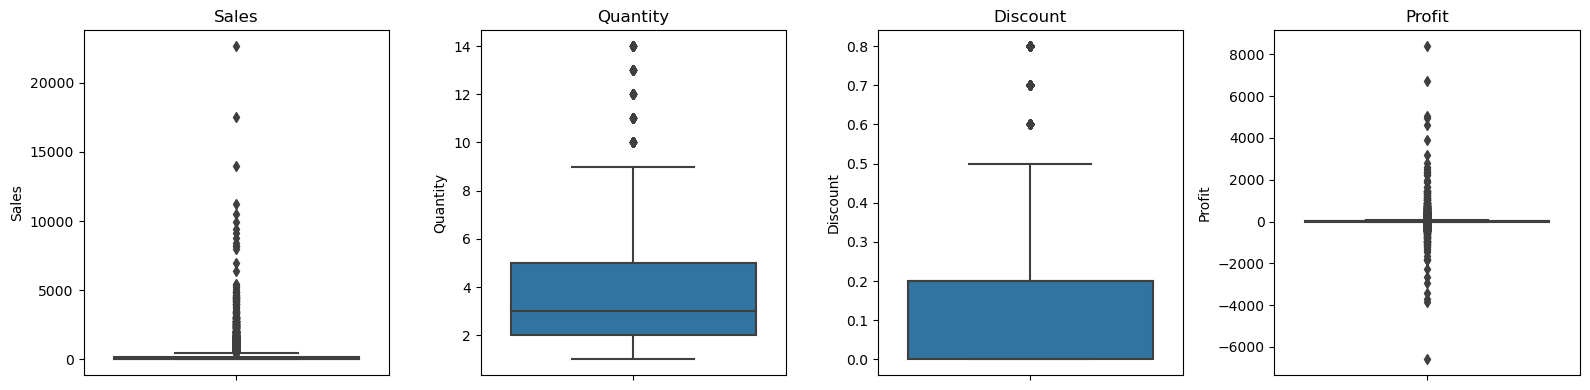

Discount < 0: 0
Discount > 1: 0
Quantity <= 0: 0
Sales <= 0: 0


In [126]:
num_cols = ['Sales','Quantity','Discount','Profit']
df[num_cols].describe()

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# границы
print('Discount < 0:', (df['Discount'] < 0).sum())
print('Discount > 1:', (df['Discount'] > 1).sum())
print('Quantity <= 0:', (df['Quantity'] <= 0).sum())
print('Sales <= 0:', (df['Sales'] <= 0).sum())

**Результат:**
- `Discount` в диапазоне [0; 0.8], аномалий нет;
- `Quantity` от 1 до 14, нулей/отрицательных нет;
- `Sales` > 0 всегда;
- выбросы в `Sales` и отрицательный `Profit` — оставлены,
  отражают дорогие товары и промо-скидки.

## 1.6. Логическая согласованность

Проверяем смысл данных, а не только типы:
- `Ship Date` не раньше `Order Date`;
- срок доставки разумный;
- один `Order ID` → один клиент и один адрес;
- даты в пределах заявленного периода;
- `Sales / Quantity` (цена за единицу) не отрицательна.

In [127]:
# 1. Ship Date >= Order Date
print('Ship раньше Order:', (df['Ship Date'] < df['Order Date']).sum())

# 2. Срок доставки
df['Ship_Days'] = (df['Ship Date'] - df['Order Date']).dt.days
print(df['Ship_Days'].describe())
print(df['Ship_Days'].value_counts().sort_index())

# 3. Один заказ — один клиент/адрес
multi = df.groupby('Order ID')[['Customer ID','City','State']].nunique()
print(multi.gt(1).sum())   # по каждому столбцу должно быть 0

# 4. Период
print('Min date:', df['Order Date'].min())
print('Max date:', df['Order Date'].max())

# 5. Цена за единицу
df['Unit_Price'] = df['Sales'] / df['Quantity']
print(df['Unit_Price'].describe())

Ship раньше Order: 0
count   9,994.00
mean        3.96
std         1.75
min         0.00
25%         3.00
50%         4.00
75%         5.00
max         7.00
Name: Ship_Days, dtype: float64
0     519
1     369
2    1334
3    1005
4    2774
5    2169
6    1203
7     621
Name: Ship_Days, dtype: int64
Customer ID    0
City           0
State          0
dtype: int64
Min date: 2014-01-03 00:00:00
Max date: 2017-12-30 00:00:00
count   9,994.00
mean       60.92
std       142.93
min         0.34
25%         5.47
50%        16.27
75%        63.94
max     3,773.08
Name: Unit_Price, dtype: float64


**Результат:**
- заказов с `Ship Date < Order Date` — 0;
- срок доставки 0–7 дней, медиана — 4 дня (Same Day = 0);
- каждый `Order ID` относится к одному клиенту и адресу;
- период заказов: 04.01.2014 – 30.12.2017;
- `Unit_Price` > 0 всегда.

## 1.7. Проверка категориальных значений

Ищем опечатки, лишние пробелы, разные регистры и неожиданные категории.
Ожидаем: 4 способа доставки, 3 сегмента, 4 региона, 3 категории, 17 подкатегорий.

In [128]:
for c in ['Ship Mode','Segment','Region','Category','Sub-Category']:
    print(f'--- {c} ---')
    print(df[c].value_counts(dropna=False))
    print()

# пробелы по краям
print('Пробелы в City:',
      df['City'].astype(str).str.contains(r'^\s|\s$', regex=True).sum())
print('Пробелы в State:',
      df['State'].astype(str).str.contains(r'^\s|\s$', regex=True).sum())

print('Уникальных штатов:', df['State'].nunique())

--- Ship Mode ---
Standard Class    5968
Second Class      1945
First Class       1538
Same Day           543
Name: Ship Mode, dtype: int64

--- Segment ---
Consumer       5191
Corporate      3020
Home Office    1783
Name: Segment, dtype: int64

--- Region ---
West       3203
East       2848
Central    2323
South      1620
Name: Region, dtype: int64

--- Category ---
Office Supplies    6026
Furniture          2121
Technology         1847
Name: Category, dtype: int64

--- Sub-Category ---
Binders        1523
Paper          1370
Furnishings     957
Phones          889
Storage         846
Art             796
Accessories     775
Chairs          617
Appliances      466
Labels          364
Tables          319
Envelopes       254
Bookcases       228
Fasteners       217
Supplies        190
Machines        115
Copiers          68
Name: Sub-Category, dtype: int64

Пробелы в City: 0
Пробелы в State: 0
Уникальных штатов: 49


**Результат:**
- категориальные признаки чистые: 4 / 3 / 4 / 3 / 17 уникальных значений;
- опечаток и вариантов написания нет;
- пробелов по краям в `City` / `State` нет;
- уникальных штатов — 49.

## 1.8. Итоговая сводка качества данных

| Проверка | Результат | Действие |
|---|---|---|
| Пропуски | 0 | — |
| Полные дубликаты строк | 0 | — |
| Повторяющиеся `Order ID` | есть | не удалять (многопозиционные заказы) |
| Дубликаты `Order ID + Product ID` | 0 | — |
| `Discount` вне [0; 1] | 0 | — |
| `Quantity` ≤ 0 | 0 | — |
| `Ship Date` < `Order Date` | 0 | — |
| `Order ID` → 1 клиент / адрес | 0 нарушений | — |
| Выбросы `Sales` / отрицательный `Profit` | есть | оставлены |
| Категориальные значения | чистые | — |

**Вывод:** данные пригодны для анализа без удаления строк.
Потребовалось приведение типов (даты, `Postal Code`,) и категориальные (`Ship Mode`, `Segment`, `Country`, `City`, `State`, `Region`, `Category`, `Sub-Category`).

## 1.9. Сохранение очищенного датасета

Сохраняем в parquet, чтобы этапы 2–4 не повторяли парсинг дат.

In [129]:
df.to_csv('superstore_clean.parquet', index=False)
print('Сохранено:', df.shape)

Сохранено: (9994, 23)


**Чек-лист этапа **

- [x] CSV загружен с корректной кодировкой (cp1251)
- [x] Даты и Postal Code приведены к правильным типам
- [x] Ship Mode, Segment, Country, City, State, Region, Category, Sub-Category к категориальному типу
- [x] Проверены пропуски, дубликаты, выбросы, границы значений
- [x] Проверена логика (Ship ≥ Order, Order ID → 1 адрес)
- [x] Проверены категориальные значения
- [x] Есть итоговая таблица качества + вывод
- [x] Очищенный датасет сохранён в parquet